In [1]:
!pip install -q monai segment-anything

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00a 0:00:01


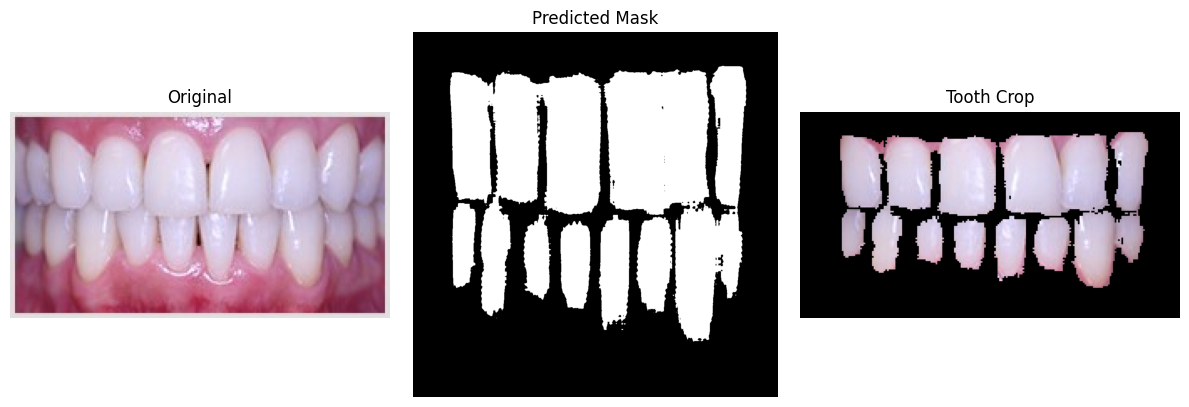

Saved tooth crop for patient9-2.jpg -> /kaggle/working/outputs/patient9-2_tooth_crop.png


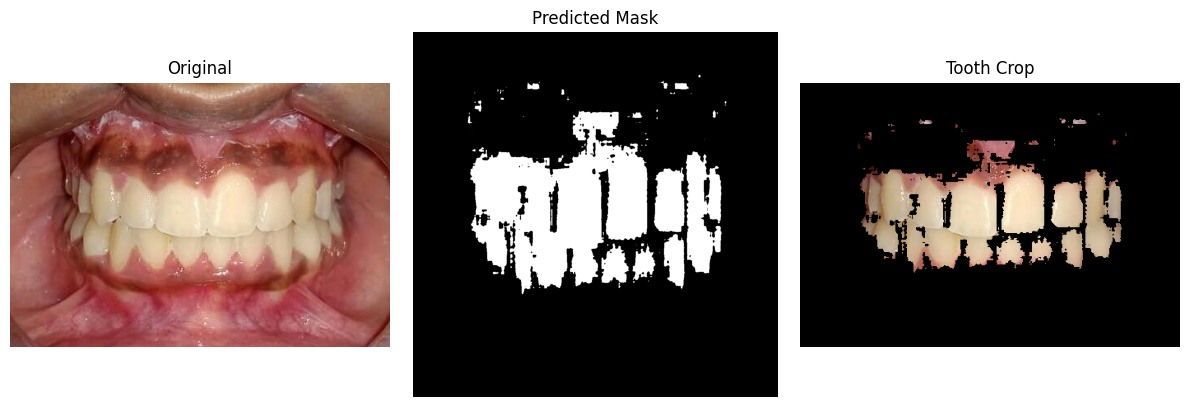

Saved tooth crop for 7836.jpg -> /kaggle/working/outputs/7836_tooth_crop.png


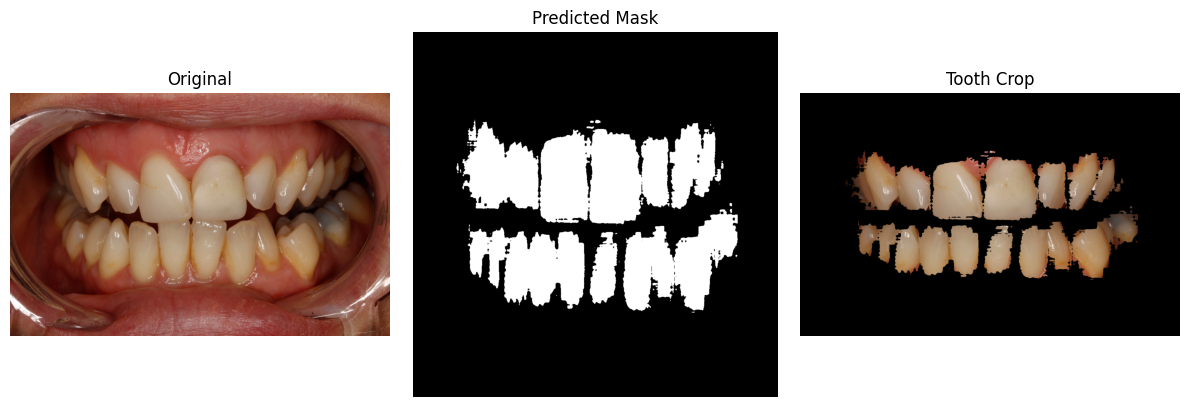

Saved tooth crop for 7018.jpg -> /kaggle/working/outputs/7018_tooth_crop.png


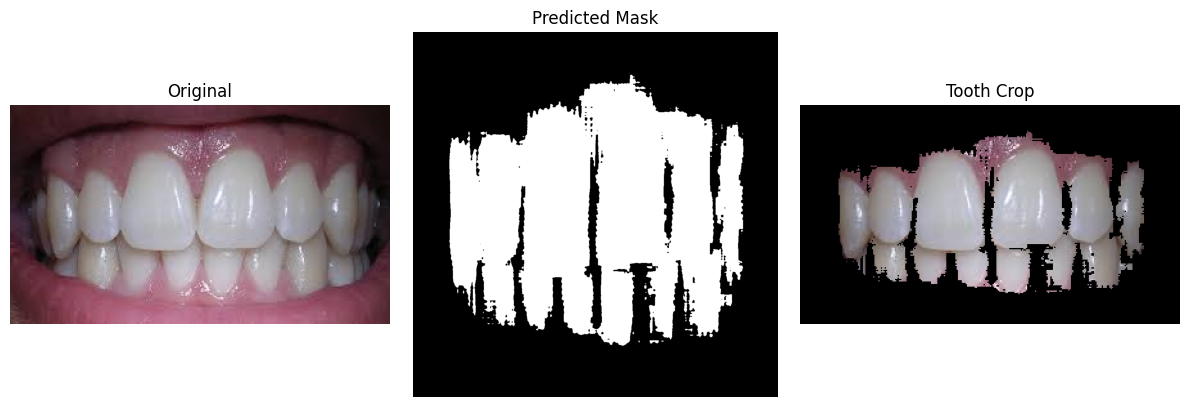

Saved tooth crop for yahya1.jpg -> /kaggle/working/outputs/yahya1_tooth_crop.png


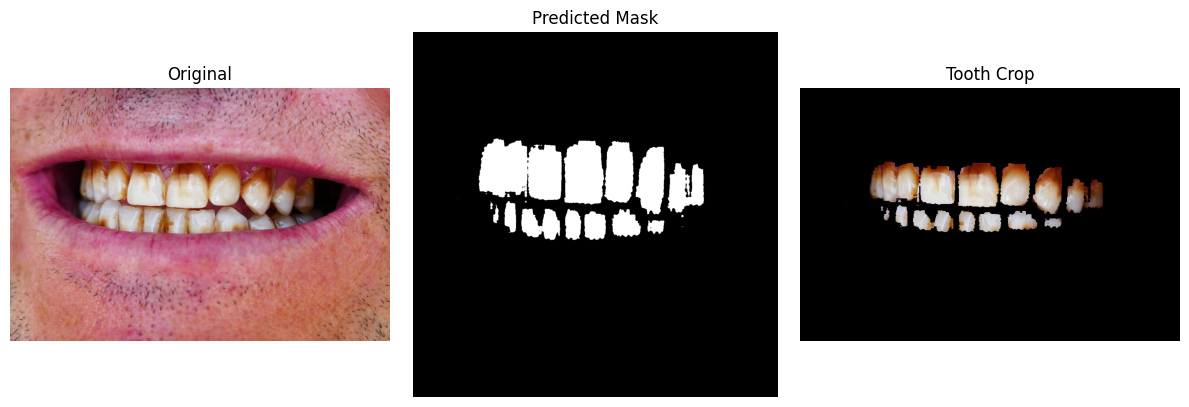

Saved tooth crop for istockphoto-1002774754-612x612.jpg -> /kaggle/working/outputs/istockphoto-1002774754-612x612_tooth_crop.png


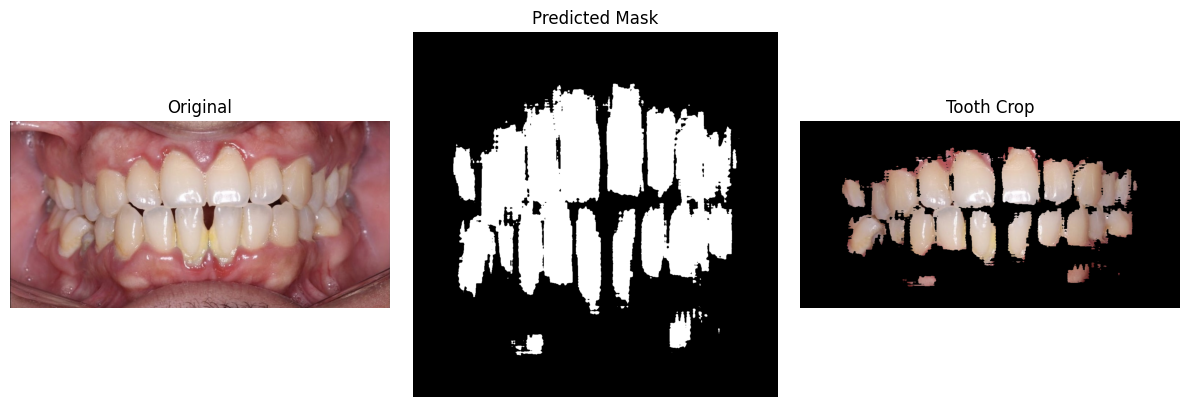

Saved tooth crop for IMG_2423.jpg -> /kaggle/working/outputs/IMG_2423_tooth_crop.png


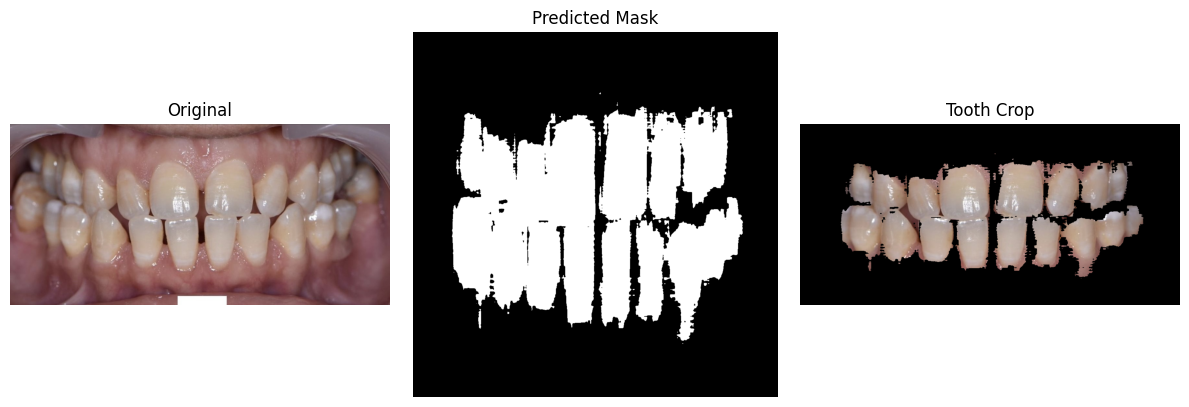

Saved tooth crop for IMG_2385.jpg -> /kaggle/working/outputs/IMG_2385_tooth_crop.png


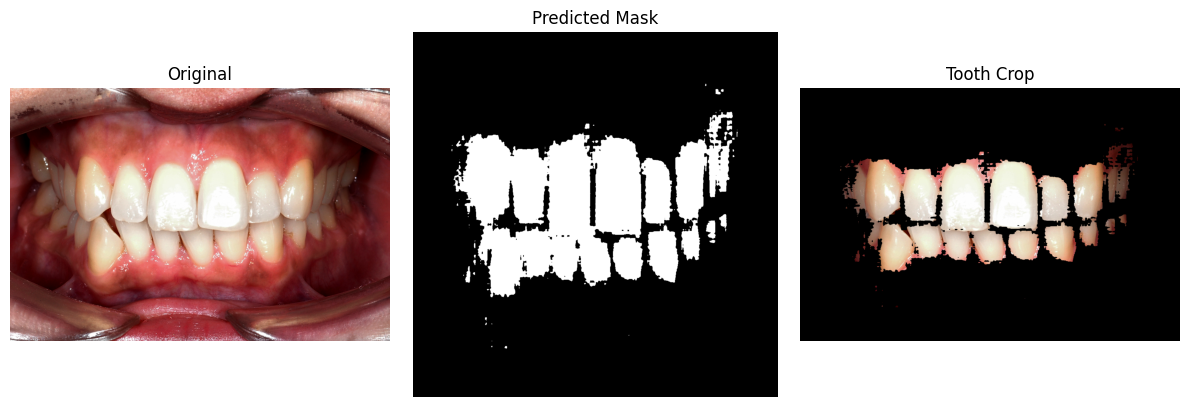

Saved tooth crop for 8764.jpg -> /kaggle/working/outputs/8764_tooth_crop.png


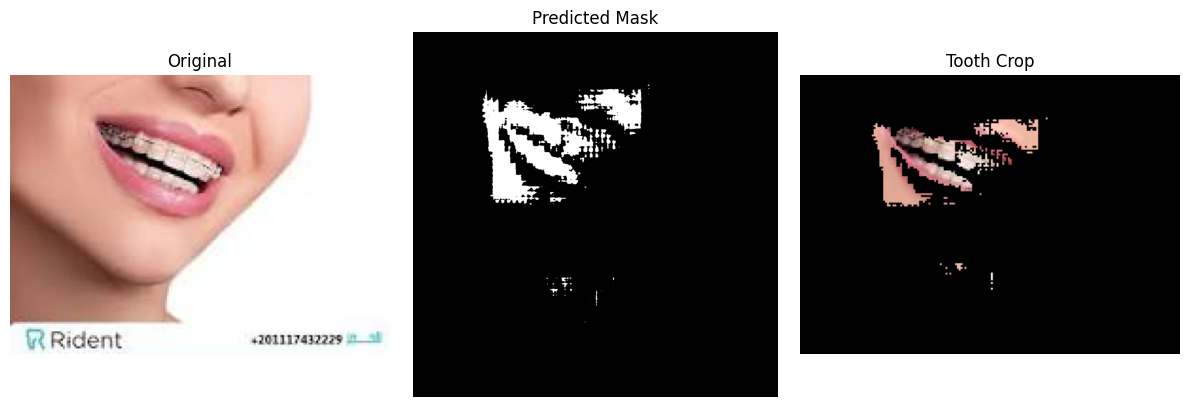

Saved tooth crop for y9.jpeg -> /kaggle/working/outputs/y9_tooth_crop.png


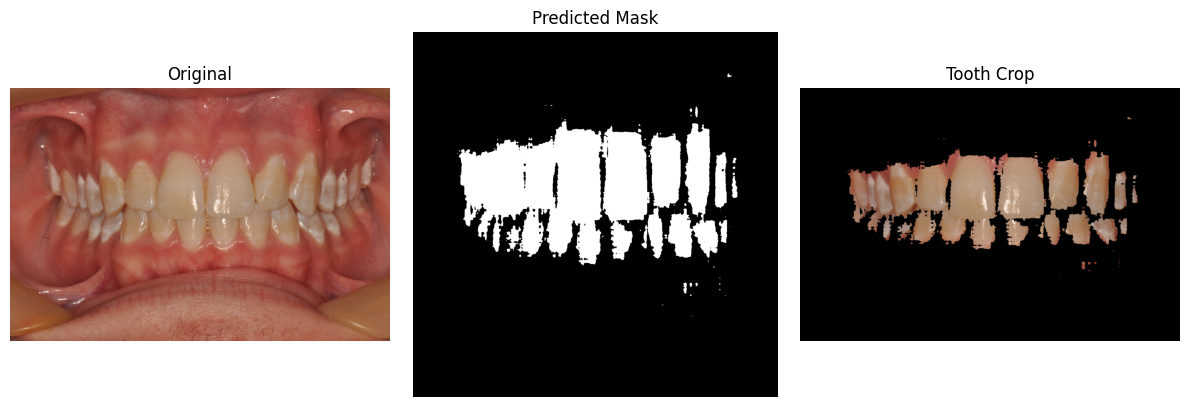

Saved tooth crop for 7758.jpg -> /kaggle/working/outputs/7758_tooth_crop.png


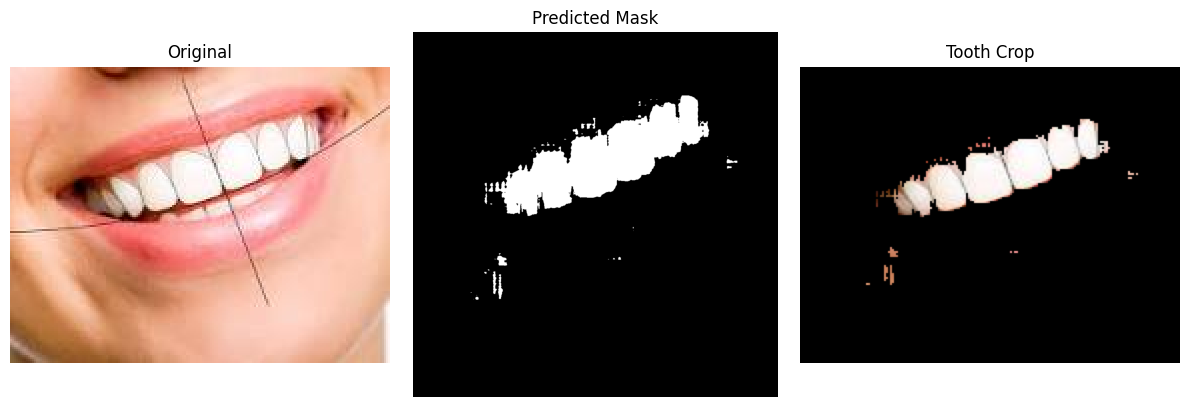

Saved tooth crop for y17.jpeg -> /kaggle/working/outputs/y17_tooth_crop.png


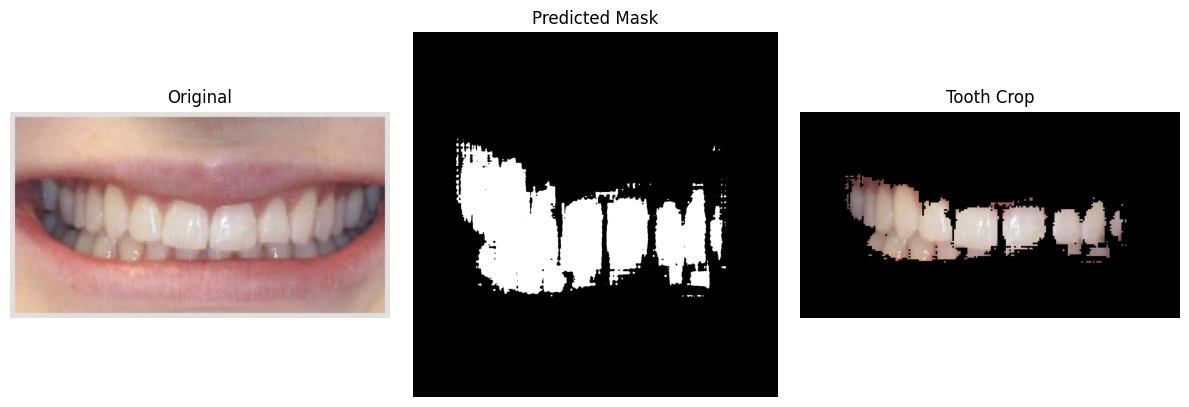

Saved tooth crop for patient17-2.jpg -> /kaggle/working/outputs/patient17-2_tooth_crop.png


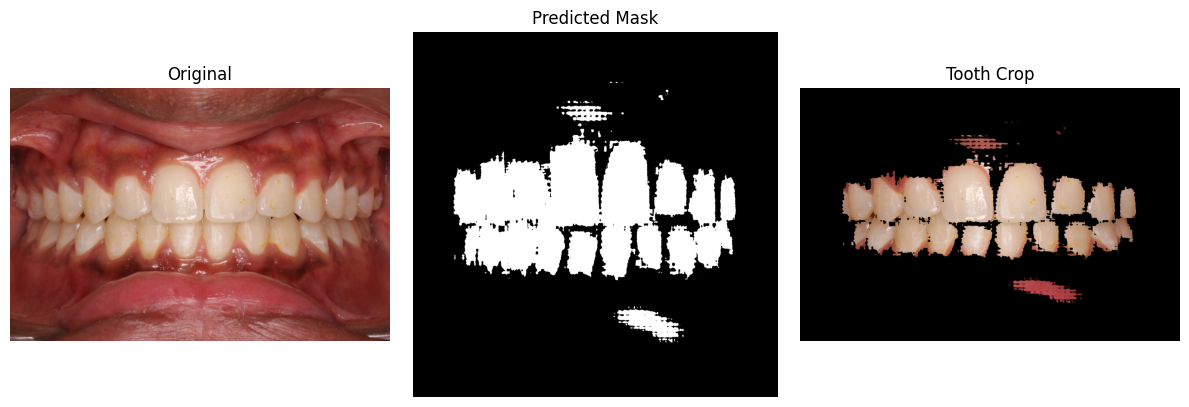

Saved tooth crop for 7625.jpg -> /kaggle/working/outputs/7625_tooth_crop.png


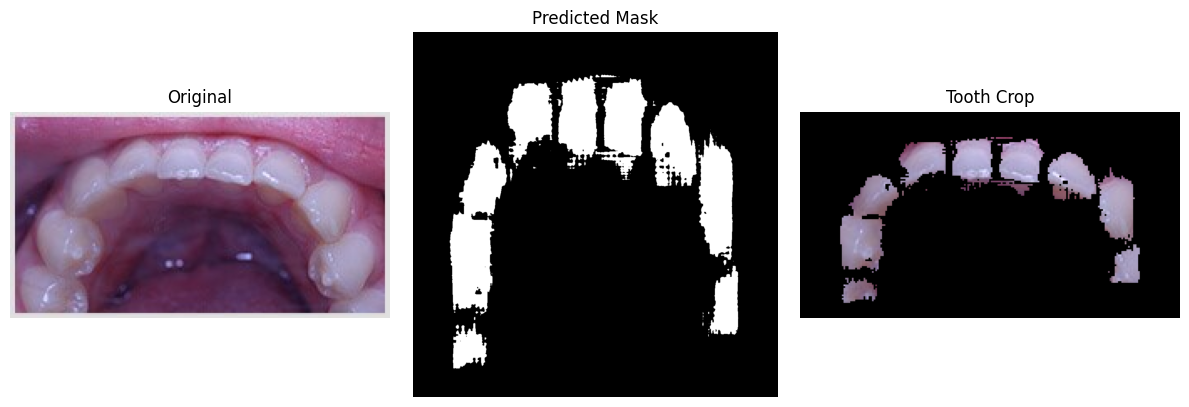

Saved tooth crop for patient4-2.jpg -> /kaggle/working/outputs/patient4-2_tooth_crop.png


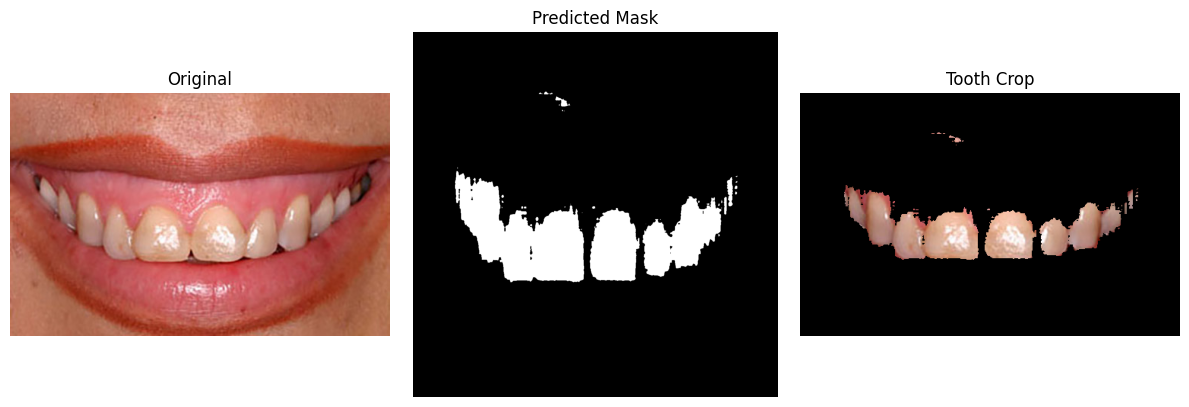

Saved tooth crop for mous15.jpg -> /kaggle/working/outputs/mous15_tooth_crop.png


In [7]:
import os
import random
import numpy as np
import torch
import torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt
from skimage.transform import resize
from segment_anything import sam_model_registry

# --------------------------------------------------------------------------
# CONSTANTS
# --------------------------------------------------------------------------
# infer.py runs in Notebook B, a separate Kaggle session from Notebook A, so
# it can't read Notebook A's /kaggle/working directly. Notebook A's trained
# checkpoint was published as its own Kaggle Dataset ("notebook-a-meowmeow")
# and attached to Notebook B, confirmed path below.
CHECKPOINT_PATH = "/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth"
OUTPUT_DIR = "/kaggle/working/outputs"
VAL_IMAGES_DIR = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/val/images"

IMG_SIZE = 1024
MASK_THRESHOLD = 0.9
NUM_SAMPLE_IMAGES = 15
RANDOM_SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# --------------------------------------------------------------------------
# MODEL LOADING
# --------------------------------------------------------------------------
def load_model(checkpoint_path):
    # vit_b architecture must match what was fine-tuned in module_2; we load
    # it with no checkpoint first, then load our fine-tuned weights on top.
    model = sam_model_registry["vit_b"](checkpoint=None)
    state_dict = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.to(DEVICE)
    model.eval()
    return model


# --------------------------------------------------------------------------
# PREPROCESSING
# --------------------------------------------------------------------------
def preprocess_image(image_path):
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    image_resized = resize(
        image_rgb, (IMG_SIZE, IMG_SIZE), order=3, preserve_range=True, anti_aliasing=True
    )
    image_normalized = (image_resized / 255.0).astype(np.float32)

    image_tensor = torch.from_numpy(image_normalized).permute(2, 0, 1).unsqueeze(0).float()
    return image_tensor, image_rgb


# --------------------------------------------------------------------------
# BBOX PROMPT (no ground truth available at inference time)
# --------------------------------------------------------------------------
def get_bbox_prompt(image_shape, margin_fraction=0.1):
    # With no GT mask to derive a bbox from, we fall back to a generous
    # centered box covering most of the image, since input photos are assumed
    # to already be roughly cropped around the mouth/teeth region.
    h, w = image_shape[:2]
    margin_x = int(w * margin_fraction)
    margin_y = int(h * margin_fraction)
    return np.array([margin_x, margin_y, w - margin_x, h - margin_y], dtype=np.float32)


# --------------------------------------------------------------------------
# INFERENCE
# --------------------------------------------------------------------------
def run_inference(model, image_tensor, bbox):
    image_tensor = image_tensor.to(DEVICE)
    box_torch = torch.as_tensor(bbox, dtype=torch.float32, device=DEVICE).view(1, 1, 4)

    with torch.no_grad():
        image_embedding = model.image_encoder(image_tensor)
        sparse_embeddings, dense_embeddings = model.prompt_encoder(
            points=None, boxes=box_torch, masks=None,
        )
        low_res_masks, _ = model.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=model.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False,
        )
        upsampled = F.interpolate(
            low_res_masks, size=image_tensor.shape[-2:], mode="bilinear", align_corners=False
        )
        probs = torch.sigmoid(upsampled)

    mask = (probs.squeeze().cpu().numpy() > MASK_THRESHOLD).astype(np.uint8)
    return mask


# --------------------------------------------------------------------------
# TOOTH CROP EXTRACTION
# --------------------------------------------------------------------------
def extract_tooth_crop(original_image, mask, save_path):
    # Resize the (1024x1024) mask back down to the original image's resolution
    # so it can be applied pixel-for-pixel.
    mask_resized = cv2.resize(
        mask, (original_image.shape[1], original_image.shape[0]), interpolation=cv2.INTER_NEAREST
    )
    mask_3ch = np.repeat(mask_resized[:, :, None], 3, axis=2)
    tooth_crop = original_image * mask_3ch  # zeroes out everything outside the tooth region

    cv2.imwrite(save_path, cv2.cvtColor(tooth_crop, cv2.COLOR_RGB2BGR))
    return tooth_crop


# --------------------------------------------------------------------------
# VISUALIZATION
# --------------------------------------------------------------------------
def visualize_result(original_image, mask, tooth_crop, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original_image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Predicted Mask")
    axes[1].axis("off")

    axes[2].imshow(tooth_crop)
    axes[2].set_title("Tooth Crop")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()


# --------------------------------------------------------------------------
# MAIN
# --------------------------------------------------------------------------
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    random.seed(RANDOM_SEED)

    model = load_model(CHECKPOINT_PATH)

    all_images = sorted(
        f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".jpeg"))
    )
    sample_images = random.sample(all_images, min(NUM_SAMPLE_IMAGES, len(all_images)))

    for filename in sample_images:
        image_path = os.path.join(VAL_IMAGES_DIR, filename)
        base_name = os.path.splitext(filename)[0]

        image_tensor, original_image = preprocess_image(image_path)
        bbox = get_bbox_prompt(image_tensor.shape[-2:])
        mask = run_inference(model, image_tensor, bbox)

        crop_path = os.path.join(OUTPUT_DIR, f"{base_name}_tooth_crop.png")
        tooth_crop = extract_tooth_crop(original_image, mask, crop_path)

        viz_path = os.path.join(OUTPUT_DIR, f"{base_name}_medsam_result.png")
        visualize_result(original_image, mask, tooth_crop, viz_path)

        print(f"Saved tooth crop for {filename} -> {crop_path}")
